# imports

In [1]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd

import importlib

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [2]:
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

In [3]:
# specific
from matplotlib import pyplot as plt

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils
sys.path.append(os.path.join(os.getcwd(), '../../../worm-control/src'))
from utils_worm_control import read_utils as read_utils_control

In [4]:
importlib.reload(read_utils)
importlib.reload(read_utils_control)

<module 'utils_worm_control.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/worm-2025-fieseler/notebooks/analysis/../../../worm-control/src/utils_worm_control/read_utils.py'>

# setup

In [5]:
ll = 'll00'
data_variant = 'gcamp'

save = True

In [6]:
# specific

# model_variant = 'ss, ns'
organism = 'worm'
manual = False
full = False

In [7]:
file_ids = list(range(0, 33+1))
# file_ids = [19]

# load

In [8]:
state_key, state_label = analysis_utils.get_plot_class(organism)
model_path = read_utils.get_model_path()

filenames = analysis_utils.read_filenames(organism, file_ids)

In [9]:
neuron_numbers = list()
for file_id in file_ids:
	filename, traces, eigenworms, discrete_states, timestamps, aux = analysis_utils.read_data(organism, file_id)
	neuron_numbers.append(traces.values.shape[1])
filename, traces, eigenworms, discrete_states, timestamps, aux = None, None, None, None, None, None

# score percentiles (ns)

In [10]:
percentiles_hgm = list()
for filename in filenames:
	neuron_scores_significant = analysis_utils.get_neuron_percentiles(filename, 'ns')
	percentiles_hgm.append(neuron_scores_significant)

In [11]:
significant_neurons_ns = list()
for filename in filenames:
	neuron_scores_significant = analysis_utils.get_significant_neurons(filename, 'ns', mode='hgm')
	significant_neurons_ns.append(neuron_scores_significant)

/tmp/ipykernel_137695/1510638561.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_box.set_yticklabels([f'{int(t)}' for t in yticks])


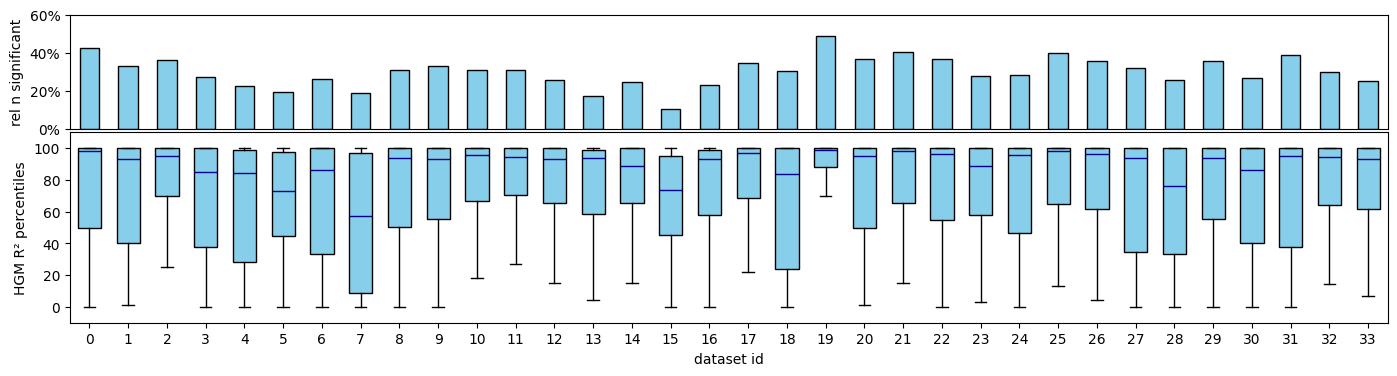

In [12]:
percentiles_hgm_1d = [np.asarray(p).ravel() for p in percentiles_hgm]
values = [neurons.values.shape[1] / n * 100 for neurons, n in zip(significant_neurons_ns, neuron_numbers)]

fig, (ax_bar, ax_box) = plt.subplots(
    nrows=2, ncols=1, figsize=(0.5*len(filenames), 4), sharex=True,
    gridspec_kw={'height_ratios': [3, 5], 'hspace': 0.02}
)

# --- Top: Bar plot of percentage values ---
ax_bar.bar(np.arange(1, len(filenames)+1), values, color='skyblue', edgecolor='black', width=0.5)
ax_bar.set_ylim(0, 60)
ax_bar.set_ylabel('rel n significant')
ax_bar.set_yticks(ax_bar.get_yticks())
ax_bar.set_yticklabels([f'{int(t)}%' for t in ax_bar.get_yticks()])
ax_bar.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)

# --- Bottom: Boxplot of percentiles ---
ax_box.boxplot(percentiles_hgm_1d, patch_artist=True,
               boxprops=dict(facecolor='skyblue', color='black'),
               medianprops=dict(color='darkblue'),
               showfliers=False,
               widths=0.6)
ax_box.set_xticks(np.arange(1, len(filenames)+1))
ax_box.set_xticklabels(range(len(filenames)))
ax_box.set_xlabel('dataset id')
ax_box.set_ylabel('HGM R² percentiles')
ax_box.set_ylim(-10, 110)
yticks = ax_box.get_yticks()
ax_box.set_yticklabels([f'{int(t)}' for t in yticks])

# Optional: annotate above each boxplot
# for i, val in enumerate(values):
#     ax_box.annotate(f'{val:.0f}%',
#                     xy=(i+1, 1), xycoords=('data', 'axes fraction'),
#                     xytext=(0, 8), textcoords='offset points',
#                     ha='center', va='bottom', fontsize=10, color='black', clip_on=False)

if save:
    plt.savefig('../../out/plots/scores/percentiles_hgm_ns_with_bar.png', bbox_inches='tight')
plt.show()


# scores (ns)

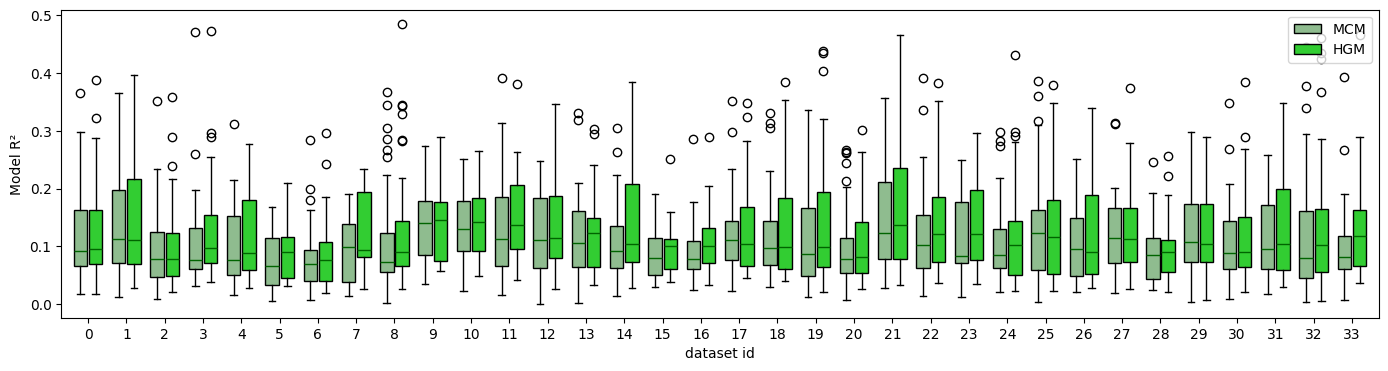

In [13]:
boxplot_values = [np.array(neurons.values[1].tolist()).squeeze() for neurons in significant_neurons_ns]
boxplot_values_bom = [np.array(neurons.values[0].tolist()).squeeze() for neurons in significant_neurons_ns]

# Prepare positions for side-by-side boxplots
positions_bom = np.arange(1, len(filenames)+1) - 0.2  # left
positions_hgm = np.arange(1, len(filenames)+1) + 0.2  # right

fig, ax_box = plt.subplots(
    nrows=1, ncols=1, figsize=(0.5*len(filenames), 4)
)

# Plot BOM boxplots (left, red)
bps_bom = ax_box.boxplot(
    boxplot_values_bom, positions=positions_bom, patch_artist=True,
    boxprops=dict(facecolor='darkseagreen', color='black'),
    medianprops=dict(color='darkgreen'),
    showfliers=True,
    widths=0.35
)
for box in bps_bom['boxes']:
    box.set_alpha(1)

# Plot HGM boxplots (right, blue)
bps = ax_box.boxplot(
    boxplot_values, positions=positions_hgm, patch_artist=True,
    boxprops=dict(facecolor='limegreen', color='black'),
    medianprops=dict(color='darkgreen'),
    showfliers=True,
    widths=0.35
)
for box in bps['boxes']:
    box.set_alpha(1)

ax_box.set_xticks(np.arange(1, len(filenames)+1))
ax_box.set_xticklabels(range(len(filenames)))
ax_box.set_xlabel('dataset id')
ax_box.set_ylabel('Model R²')
ax_box.legend(
    [bps_bom['boxes'][0], bps['boxes'][0]],
    ['MCM', 'HGM'],
    loc='upper right'
)

if save:
    plt.savefig('../../out/plots/scores/hgm-mcm-ns-score-distributions.png', bbox_inches='tight')

plt.show()

In [14]:
significant_neurons_ns_impr = list()
for filename in filenames:
	neuron_scores_significant = analysis_utils.get_significant_neurons(filename, 'ns', mode='impr')
	significant_neurons_ns_impr.append(neuron_scores_significant)

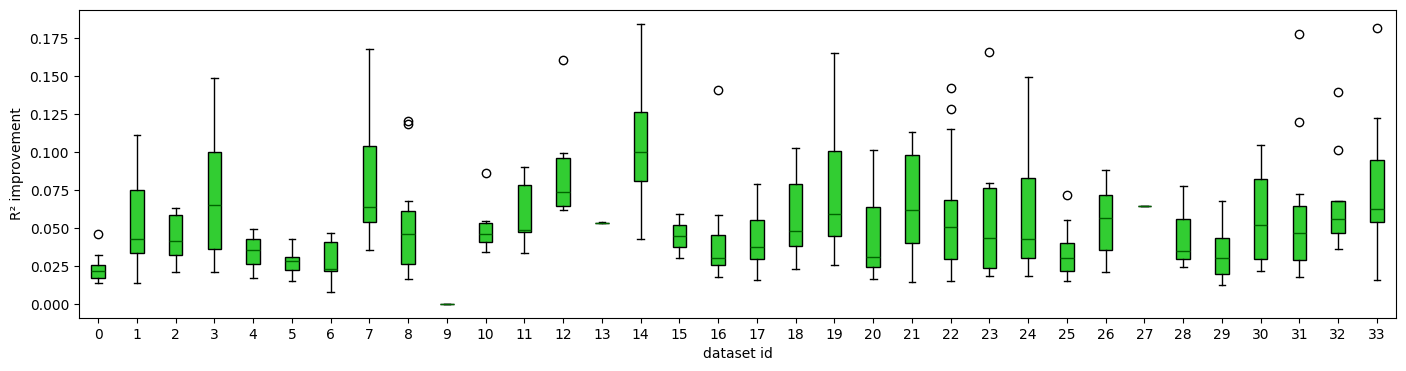

In [25]:
boxplot_values = [np.array(neurons.values[1].tolist()).squeeze() - np.array(neurons.values[0].tolist()).squeeze() if len(neurons) > 0 else np.empty(()) for neurons in significant_neurons_ns_impr]

# Prepare positions for side-by-side boxplots
positions = np.arange(1, len(filenames)+1)

fig, ax_box = plt.subplots(
    nrows=1, ncols=1, figsize=(0.5*len(filenames), 4)
)

# Plot BOM boxplots (left, red)
bps = ax_box.boxplot(
    boxplot_values, positions=positions, patch_artist=True,
    boxprops=dict(facecolor='limegreen', color='black'),
    medianprops=dict(color='darkgreen'),
    showfliers=True,
    widths=0.35
)
for box in bps['boxes']:
    box.set_alpha(1)

ax_box.set_xticks(np.arange(1, len(filenames)+1))
ax_box.set_xticklabels(range(len(filenames)))
ax_box.set_xlabel('dataset id')
ax_box.set_ylabel('R² improvement')
# ax_box.legend(
#     [bps_bom['boxes'][0], bps['boxes'][0]],
#     ['MCM', 'HGM'],
#     loc='upper right'
# )

if save:
    plt.savefig('../../out/plots/scores/ns-improvement-distributions.png', bbox_inches='tight')

plt.show()

# score percentiles (ss)

In [16]:
significant_neurons_ss = list()
for filename in filenames:
	neuron_scores_significant = analysis_utils.get_significant_neurons(filename, 'ss', mode='hgm')
	significant_neurons_ss.append(neuron_scores_significant)

In [17]:
percentiles_hgm = list()
for filename in filenames:
	neuron_scores_significant = analysis_utils.get_neuron_percentiles(filename, 'ss')
	percentiles_hgm.append(neuron_scores_significant)

/tmp/ipykernel_137695/3366206881.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_box.set_yticklabels([f'{int(t)}%' for t in yticks])


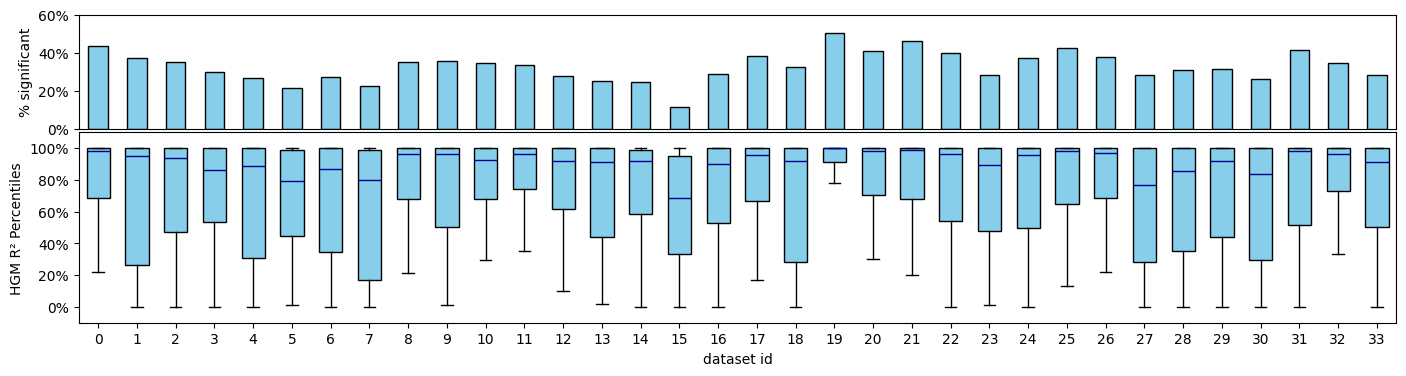

In [18]:
percentiles_hgm_1d = [np.asarray(p).ravel() for p in percentiles_hgm]
values = [neurons.values.shape[1] / n * 100 for neurons, n in zip(significant_neurons_ss, neuron_numbers)]

fig, (ax_bar, ax_box) = plt.subplots(
    nrows=2, ncols=1, figsize=(0.5*len(filenames), 4), sharex=True,
    gridspec_kw={'height_ratios': [3, 5], 'hspace': 0.02}
)

# --- Top: Bar plot of percentage values ---
ax_bar.bar(np.arange(1, len(filenames)+1), values, color='skyblue', edgecolor='black', width=0.5)
ax_bar.set_ylim(0, 60)
ax_bar.set_ylabel('% significant')
ax_bar.set_yticks(ax_bar.get_yticks())
ax_bar.set_yticklabels([f'{int(t)}%' for t in ax_bar.get_yticks()])
ax_bar.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)

# --- Bottom: Boxplot of percentiles ---
ax_box.boxplot(percentiles_hgm_1d, patch_artist=True,
               boxprops=dict(facecolor='skyblue', color='black'),
               medianprops=dict(color='darkblue'),
               showfliers=False,
               widths=0.6)
ax_box.set_xticks(np.arange(1, len(filenames)+1))
ax_box.set_xticklabels(range(len(filenames)))
ax_box.set_xlabel('dataset id')
ax_box.set_ylabel('HGM R² Percentiles')
ax_box.set_ylim(-10, 110)
yticks = ax_box.get_yticks()
ax_box.set_yticklabels([f'{int(t)}%' for t in yticks])

# Optional: annotate above each boxplot
# for i, val in enumerate(values):
#     ax_box.annotate(f'{val:.0f}%',
#                     xy=(i+1, 1), xycoords=('data', 'axes fraction'),
#                     xytext=(0, 8), textcoords='offset points',
#                     ha='center', va='bottom', fontsize=10, color='black', clip_on=False)

if save:
    plt.savefig('../../out/plots/scores/percentiles_hgm_ss_with_bar.png', bbox_inches='tight')
plt.show()


# scores (ss)

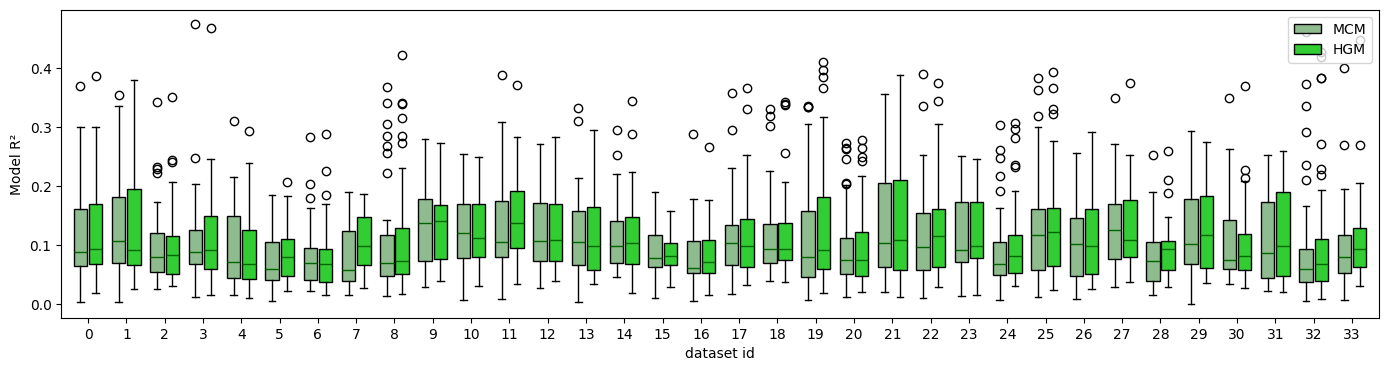

In [20]:
boxplot_values = [np.array(neurons.values[1].tolist()).squeeze() for neurons in significant_neurons_ss]
boxplot_values_bom = [np.array(neurons.values[0].tolist()).squeeze() for neurons in significant_neurons_ss]

# Prepare positions for side-by-side boxplots
positions_bom = np.arange(1, len(filenames)+1) - 0.2  # left
positions_hgm = np.arange(1, len(filenames)+1) + 0.2  # right

fig, ax_box = plt.subplots(
    nrows=1, ncols=1, figsize=(0.5*len(filenames), 4)
)

# Plot BOM boxplots (left, red)
bps_bom = ax_box.boxplot(
    boxplot_values_bom, positions=positions_bom, patch_artist=True,
    boxprops=dict(facecolor='darkseagreen', color='black'),
    medianprops=dict(color='darkgreen'),
    showfliers=True,
    widths=0.35
)
for box in bps_bom['boxes']:
    box.set_alpha(1)

# Plot HGM boxplots (right, blue)
bps = ax_box.boxplot(
    boxplot_values, positions=positions_hgm, patch_artist=True,
    boxprops=dict(facecolor='limegreen', color='black'),
    medianprops=dict(color='darkgreen'),
    showfliers=True,
    widths=0.35
)
for box in bps['boxes']:
    box.set_alpha(1)

ax_box.set_xticks(np.arange(1, len(filenames)+1))
ax_box.set_xticklabels(range(len(filenames)))
ax_box.set_xlabel('dataset id')
ax_box.set_ylabel('Model R²')
ax_box.legend(
    [bps_bom['boxes'][0], bps['boxes'][0]],
    ['MCM', 'HGM'],
    loc='upper right'
)

if save:
    plt.savefig('../../out/plots/scores/hgm-mcm-ss-score-distributions.png', bbox_inches='tight')

plt.show()

In [21]:
significant_neurons_ss_impr = list()
for filename in filenames:
	neuron_scores_significant = analysis_utils.get_significant_neurons(filename, 'ss', mode='impr')
	significant_neurons_ss_impr.append(neuron_scores_significant)

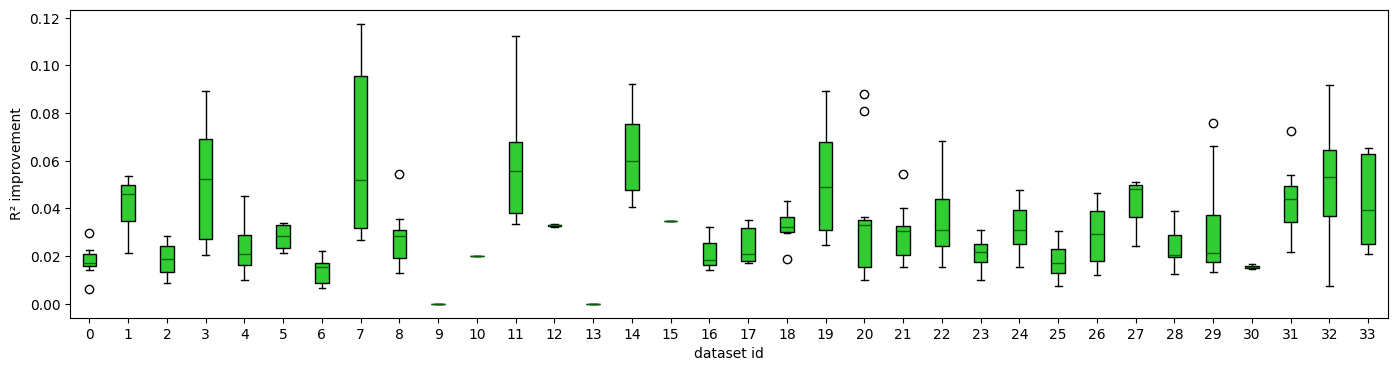

In [26]:
boxplot_values = [np.array(neurons.values[1].tolist()).squeeze() - np.array(neurons.values[0].tolist()).squeeze() if len(neurons) > 0 else np.empty(()) for neurons in significant_neurons_ss_impr]

# Prepare positions for side-by-side boxplots
positions = np.arange(1, len(filenames)+1)

fig, ax_box = plt.subplots(
    nrows=1, ncols=1, figsize=(0.5*len(filenames), 4)
)

# Plot BOM boxplots (left, red)
bps = ax_box.boxplot(
    boxplot_values, positions=positions, patch_artist=True,
    boxprops=dict(facecolor='limegreen', color='black'),
    medianprops=dict(color='darkgreen'),
    showfliers=True,
    widths=0.35
)
for box in bps['boxes']:
    box.set_alpha(1)

ax_box.set_xticks(np.arange(1, len(filenames)+1))
ax_box.set_xticklabels(range(len(filenames)))
ax_box.set_xlabel('dataset id')
ax_box.set_ylabel('R² improvement')
# ax_box.legend(
#     [bps_bom['boxes'][0], bps['boxes'][0]],
#     ['MCM', 'HGM'],
#     loc='upper right'
# )

if save:
    plt.savefig('../../out/plots/scores/ss-improvement-distributions.png', bbox_inches='tight')

plt.show()